# 03 Exploratory Data Analysis

This notebook studies generated customer and order behaviour before modelling. The results describe synthetic assumptions, not real-world fraud patterns.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for path in [current, *current.parents]:
        if (path / "src").exists() and (path / "data").exists():
            return path
    raise RuntimeError("Run this notebook from inside the EcomPolice project.")

PROJECT_ROOT = find_project_root()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

CLEAN_DIR = PROJECT_ROOT / "data" / "synthetic" / "clean"
MESSY_DIR = PROJECT_ROOT / "data" / "synthetic" / "messy"
LABELS_DIR = PROJECT_ROOT / "data" / "synthetic" / "labels"
MANIFESTS_DIR = PROJECT_ROOT / "data" / "synthetic" / "manifests"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

def load_tables(base_dir: Path) -> dict[str, pd.DataFrame]:
    return {
        "customers": pd.read_csv(base_dir / "customers.csv"),
        "products": pd.read_csv(base_dir / "products.csv"),
        "orders": pd.read_csv(base_dir / "orders.csv"),
        "deliveries": pd.read_csv(base_dir / "deliveries.csv"),
        "returns": pd.read_csv(base_dir / "returns.csv"),
    }

clean_tables = load_tables(CLEAN_DIR)
labels = pd.read_csv(LABELS_DIR / 'order_ground_truth.csv')
orders = clean_tables['orders']; products = clean_tables['products']; returns = clean_tables['returns']; deliveries = clean_tables['deliveries']; customers = clean_tables['customers']
order_level = orders.merge(products, on='Product_ID').merge(returns, on='Order_ID').merge(deliveries, on='Order_ID').merge(labels, on=['Order_ID','Customer_ID'])
order_level['Order_Date'] = pd.to_datetime(order_level['Order_Date'])
order_level['Delivery_Date'] = pd.to_datetime(order_level['Delivery_Date'])
order_level['Return_Date'] = pd.to_datetime(order_level['Return_Date'], errors='coerce')
order_level['Is_Returned'] = order_level['Return_Status'].ne('Not Returned')


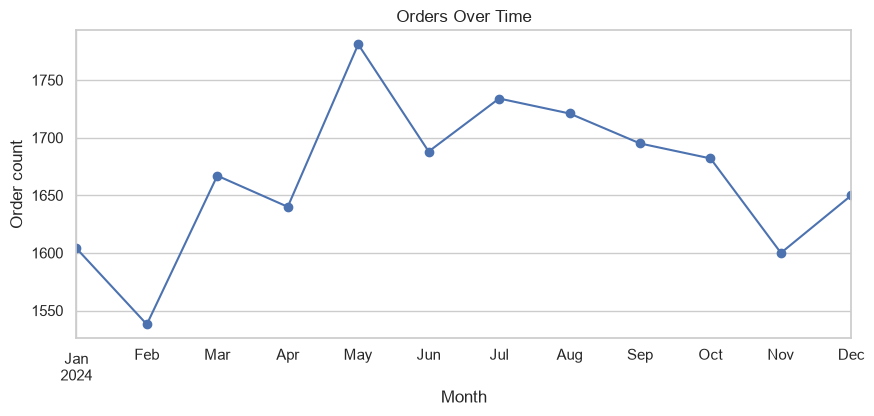

,orders
Order_Date,
2024-08-31,1721
2024-09-30,1695
2024-10-31,1682
2024-11-30,1600
2024-12-31,1650


In [2]:
monthly = order_level.set_index('Order_Date').resample('ME')['Order_ID'].count()
ax = monthly.plot(figsize=(10,4), marker='o', title='Orders Over Time')
ax.set_xlabel('Month')
ax.set_ylabel('Order count')
plt.show()
display(monthly.to_frame('orders').tail())


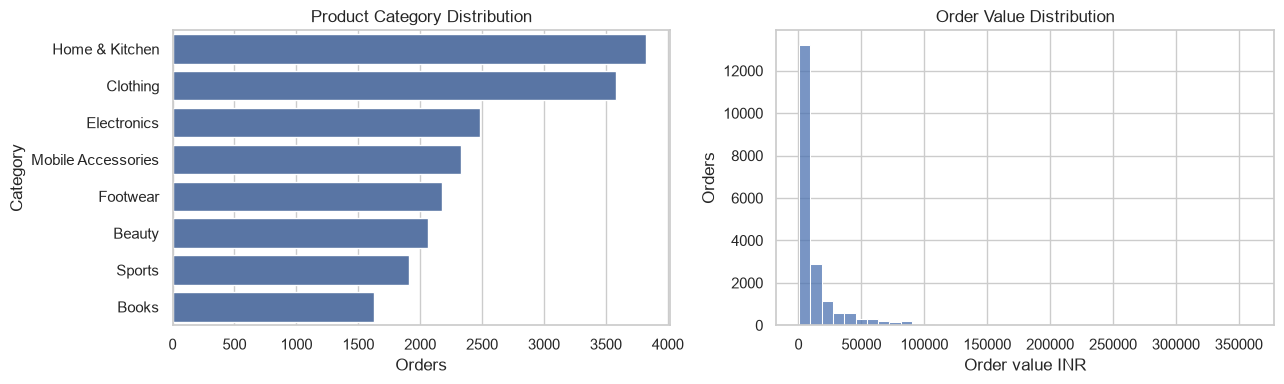

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=order_level, y='Category', order=order_level['Category'].value_counts().index, ax=axes[0])
axes[0].set_title('Product Category Distribution'); axes[0].set_xlabel('Orders'); axes[0].set_ylabel('Category')
sns.histplot(order_level['Order_Value_INR'], bins=40, ax=axes[1])
axes[1].set_title('Order Value Distribution'); axes[1].set_xlabel('Order value INR'); axes[1].set_ylabel('Orders')
plt.tight_layout(); plt.show()


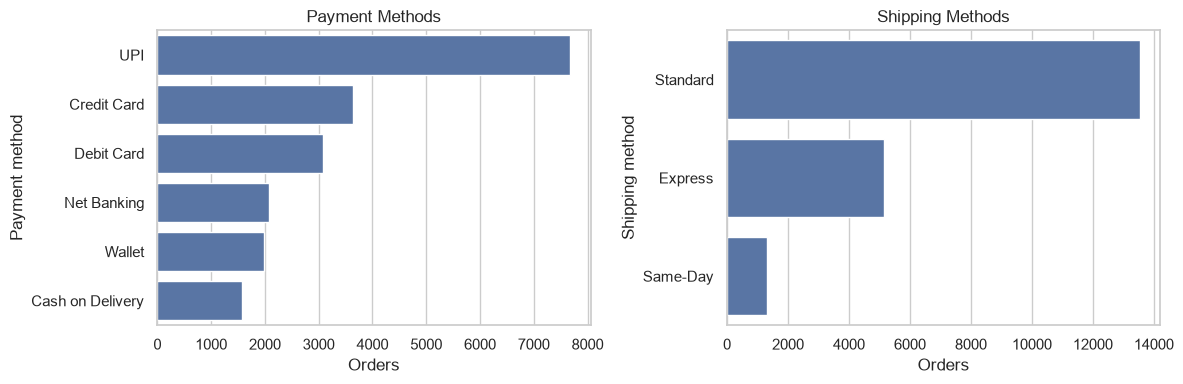

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=order_level, y='Payment_Method', order=order_level['Payment_Method'].value_counts().index, ax=axes[0])
axes[0].set_title('Payment Methods'); axes[0].set_xlabel('Orders'); axes[0].set_ylabel('Payment method')
sns.countplot(data=order_level, y='Shipping_Method', order=order_level['Shipping_Method'].value_counts().index, ax=axes[1])
axes[1].set_title('Shipping Methods'); axes[1].set_xlabel('Orders'); axes[1].set_ylabel('Shipping method')
plt.tight_layout(); plt.show()


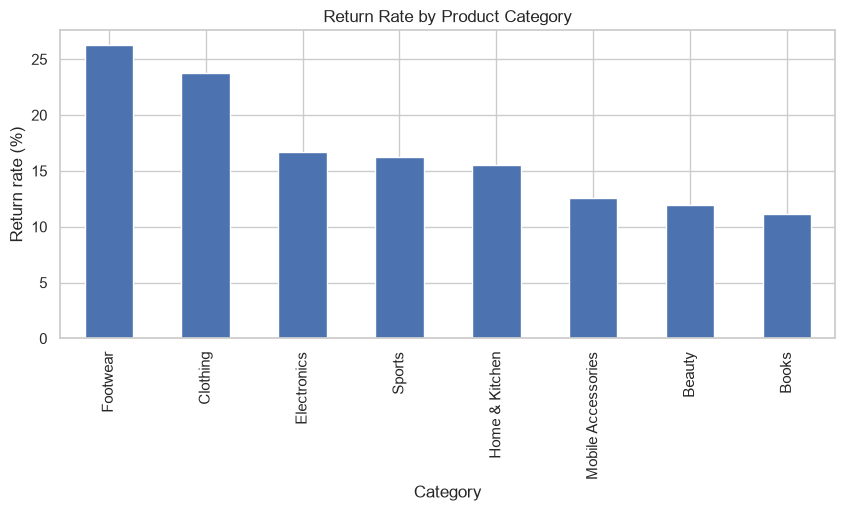

Category
Footwear              26.26
Clothing              23.80
Electronics           16.72
Sports                16.21
Home & Kitchen        15.57
Mobile Accessories    12.60
Beauty                11.92
Books                 11.15
Name: return_rate_pct, dtype: float64

In [5]:
category_return = order_level.groupby('Category')['Is_Returned'].mean().sort_values(ascending=False).mul(100).rename('return_rate_pct')
ax = category_return.plot(kind='bar', figsize=(10,4), title='Return Rate by Product Category')
ax.set_xlabel('Category'); ax.set_ylabel('Return rate (%)')
plt.show()
display(category_return.round(2))


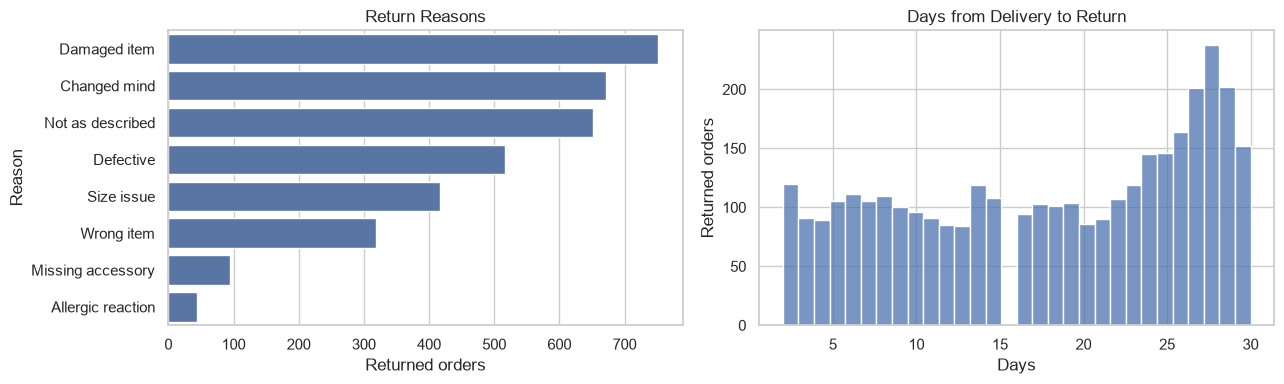

In [6]:
returned = order_level[order_level['Is_Returned']].copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=returned, y='Return_Reason', order=returned['Return_Reason'].value_counts().index, ax=axes[0])
axes[0].set_title('Return Reasons'); axes[0].set_xlabel('Returned orders'); axes[0].set_ylabel('Reason')
returned['Delivery_Delay_Days'] = (returned['Delivery_Date'] - pd.to_datetime(returned['Dispatch_Date'])).dt.days
returned['Return_Duration_Days'] = (returned['Return_Date'] - returned['Delivery_Date']).dt.days
sns.histplot(returned['Return_Duration_Days'], bins=30, ax=axes[1])
axes[1].set_title('Days from Delivery to Return'); axes[1].set_xlabel('Days'); axes[1].set_ylabel('Returned orders')
plt.tight_layout(); plt.show()


In [7]:
customer_behaviour = order_level.groupby('Customer_ID').agg(order_count=('Order_ID','count'), return_count=('Is_Returned','sum'), scenario=('Scenario_Label','first'))
customer_behaviour['return_rate'] = customer_behaviour['return_count'] / customer_behaviour['order_count']
display(customer_behaviour.describe())
display(customer_behaviour.groupby('scenario')[['order_count','return_count','return_rate']].mean().round(3))


,order_count,return_count,return_rate
count,2996.000000,2996.000000,2996.000000
mean,6.675567,1.156876,0.166226
std,2.762898,1.255674,0.168413
min,1.000000,0.000000,0.000000
25%,5.000000,0.000000,0.000000
50%,6.000000,1.000000,0.142857
75%,8.000000,2.000000,0.250000
max,20.000000,9.000000,1.000000


,order_count,return_count,return_rate
scenario,,,
FREQUENT_LEGITIMATE_RETURNS,8.767,2.000,0.223
HIGH_VALUE_RETURN_PATTERN,7.413,1.615,0.215
MIXED_SUSPICIOUS_PATTERN,9.490,3.314,0.343
NORMAL,6.197,0.855,0.140
REPEATED_DEFECT_CLAIMS,7.829,2.462,0.309
RETURN_WINDOW_PATTERN,7.610,1.870,0.245


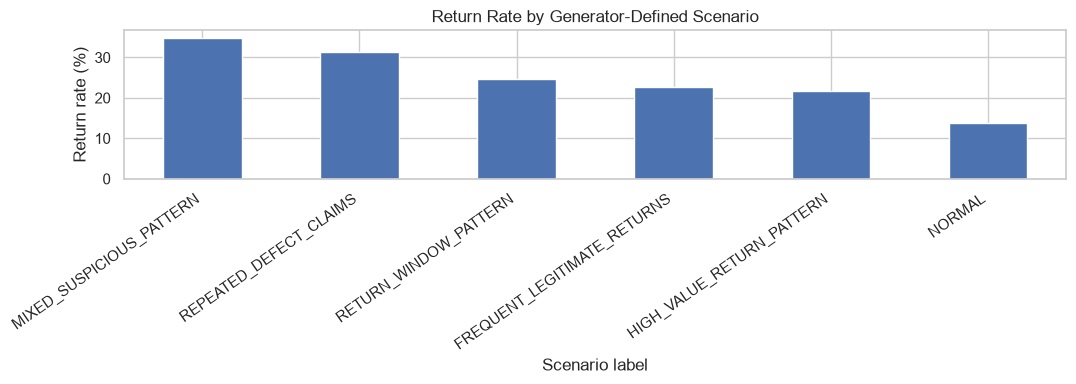

In [8]:
scenario_rates = order_level.groupby('Scenario_Label')['Is_Returned'].mean().sort_values(ascending=False).mul(100)
ax = scenario_rates.plot(kind='bar', figsize=(11,4), title='Return Rate by Generator-Defined Scenario')
ax.set_xlabel('Scenario label'); ax.set_ylabel('Return rate (%)')
plt.xticks(rotation=35, ha='right'); plt.tight_layout(); plt.show()


## Interpretation

Scenario groups differ because the generator intentionally created behavioural patterns. These differences are useful for demonstrating analysis and leakage-aware preprocessing, but they are not evidence that similar real customers are abusive. High return rate alone should be treated as a signal for review, not proof.
